In [5]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.initializers import glorot_normal, he_normal
from tensorflow.keras.regularizers import l2
import matplotlib.pyplot as plt

In [6]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

X_train, X_test = X_train.reshape(-1,32*32*3), X_test.reshape(-1,32*32*3)

X_train = X_train / 255.0
X_test = X_test / 255.0

y_train, y_test = to_categorical(y_train, 10), to_categorical(y_test, 10)

In [10]:
model_baseline = Sequential([
    Dense(256, activation='relu',input_shape=(32*32*3,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [11]:
model_baseline.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])


In [13]:
history = model_baseline.fit(X_train, y_train, validation_split=0.2, batch_size=64, epochs=20)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5560 - loss: 1.2327 - val_accuracy: 0.4976 - val_loss: 1.4619
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5664 - loss: 1.2132 - val_accuracy: 0.5000 - val_loss: 1.4461
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5678 - loss: 1.2071 - val_accuracy: 0.5009 - val_loss: 1.4420
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5710 - loss: 1.1938 - val_accuracy: 0.4776 - val_loss: 1.5104
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5764 - loss: 1.1823 - val_accuracy: 0.4839 - val_loss: 1.5188
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5800 - loss: 1.1700 - val_accuracy: 0.4969 - val_loss: 1.4628
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5836 - loss: 1.1661 - val_accuracy: 0.4910 - val_loss: 1.4845
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5879 - loss: 1.1466 - val_accuracy: 0.

In [16]:
model_xavier = Sequential([
    Dense(256, activation='relu', input_shape=(32*32*3,), kernel_initializer=glorot_normal()),
    Dense(128,activation='relu', kernel_initializer=glorot_normal()),
    Dense(64, activation='relu', kernel_initializer=glorot_normal()),
    Dense(10, activation='softmax', kernel_initializer=glorot_normal())
])

In [19]:
model_xavier.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [20]:
history_xavier = model_xavier.fit(X_train, y_train, validation_split=0.2, batch_size=64, epochs=20)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3110 - loss: 1.9083 - val_accuracy: 0.3606 - val_loss: 1.7811
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3891 - loss: 1.7088 - val_accuracy: 0.3919 - val_loss: 1.7242
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4152 - loss: 1.6283 - val_accuracy: 0.4124 - val_loss: 1.6484
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4357 - loss: 1.5766 - val_accuracy: 0.4320 - val_loss: 1.5881
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4489 - loss: 1.5356 - val_accuracy: 0.4518 - val_loss: 1.5453
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4611 - loss: 1.5066 - val_accuracy: 0.4574 - val_loss: 1.5301
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4745 - loss: 1.4734 - val_accuracy: 0.4661 - val_loss: 1.5173
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.4816 - loss: 1.4450 - val_accuracy: 0.

In [21]:
model_kaiming = Sequential([
    Dense(256, activation='relu', input_shape=(32*32*3,), kernel_initializer=he_normal()),
    Dense(128, activation='relu', kernel_initializer=he_normal()),
    Dense(64, activation='relu', kernel_initializer=he_normal()),
    Dense(10, activation='softmax', kernel_initializer=he_normal())
])

In [22]:
model_kaiming.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [23]:
history_kaiming = model_kaiming.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=64, verbose=0)

In [24]:
model_dropout = Sequential([
    Dense(256, activation='relu', input_shape=(32*32*3,)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

In [25]:
model_dropout.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [26]:
history_dropout = model_dropout.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=64, verbose=0)

In [28]:
model_l2.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [29]:
history_l2 = model_l2.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=64, verbose=0)

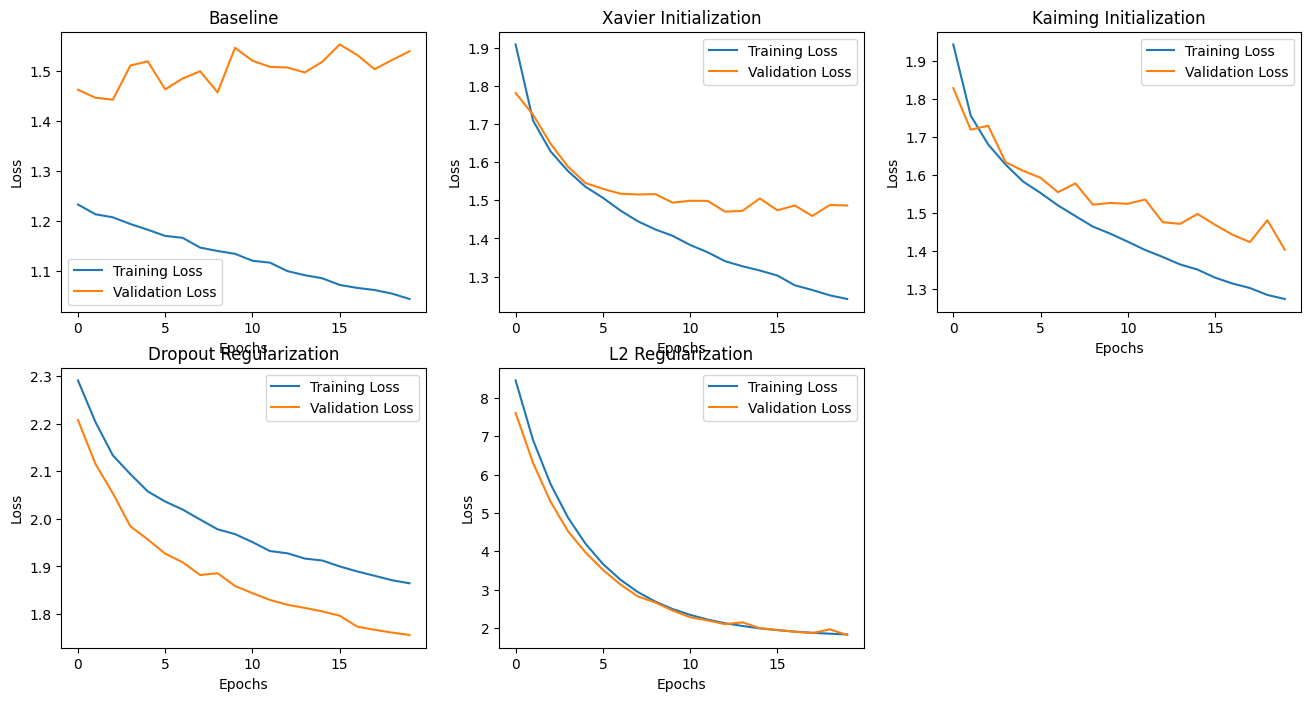

In [30]:
plt.figure(figsize=(16,8))
for i, (history, model_name) in enumerate([(history, 'Baseline'), (history_xavier, 'Xavier Initialization'),
                                           (history_kaiming, 'Kaiming Initialization'), (history_dropout, 'Dropout Regularization'),
                                           (history_l2, 'L2 Regularization')], 1):
    plt.subplot(2, 3, i)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title(model_name)

plt.show()


In [32]:
models = [model_baseline, model_xavier, model_kaiming, model_dropout, model_l2]
model_names = ['Baseline', 'Xavier Initialization', 'Kaiming Initialization', 'Dropout Regularization', 'L2 Regularization']

for model, name in zip(models, model_names):
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    print(f"Test accuracy ({name}): {test_accuracy}")


Test accuracy (Baseline): 0.49239999055862427
Test accuracy (Xavier Initialization): 0.4860000014305115
Test accuracy (Kaiming Initialization): 0.511900007724762
Test accuracy (Dropout Regularization): 0.38449999690055847
Test accuracy (L2 Regularization): 0.45730000734329224
